# Annual loss as frequency times severity: a first Monte Carlo capital

**Question:** How much capital does a synthetic bank of EUR 50 billion in assets need against operational risk at the 99.9% level, and how many simulated years does a Monte Carlo estimate of it need before it can be trusted?


- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01 (install the engine and open an artifact)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- write the annual operational loss of a bank as a compound sum, a random number of losses each with a random size;
- read a Poisson frequency and a generalised Pareto severity from a committed document and draw their quantiles and moments with the engine;
- simulate one year by hand and many years with `simulate_annual_losses`, and read the 99.9% Monte Carlo quantile and its standard error;
- say why a 99.9% quantile needs far more simulated years than a mean, and compare your estimate with the true value the case commits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data come from case C17 (operational risk: the loss distribution approach against the standardised approach). No event-level operational loss data are public (a bank's loss database is confidential), so Contraste does not use real events. It builds a **synthetic bank of EUR 50 billion in assets** whose losses come from a generator with a known truth, calibrated to the medians that the Basel Committee published for its 2008 Loss Data Collection Exercise (BCBS, 2009; licence class `derived-only`: only four percentiles and one frequency are used, with their source). The generator draws a Poisson number of losses a year and gives each a generalised Pareto size above a floor of EUR 10,000.

- **Files read:** `data/derived/C17/xi-0-8.json` (key `outputs.truth`: the true frequency, severity and 99.9% annual-loss quantile of the variant with tail index 0.8) and `data/derived/C17/models-generator.json` (the four variants side by side).
- **Why a known truth:** because the generator is ours, the exact annual loss distribution is known, so any capital number we estimate can be compared with the right answer. That is what makes the case a validation case.

The next cell loads both documents and prints the true parameters of the variant.

In [2]:
# Load the variant document and the generator document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C17 = ROOT / "data" / "derived" / "C17"
variant = json.loads((C17 / "xi-0-8.json").read_text(encoding="utf-8"))
generator_doc = json.loads((C17 / "models-generator.json").read_text(encoding="utf-8"))

truth = variant["outputs"]["truth"]
lam = truth["frequency"]["lambda_per_year"]
severity = truth["severity"]
sev_params = (severity["tail_index"], severity["scale_eur"], severity["location_eur"])
print("truth status:", variant["provenance"]["truth_status"])
print(
    "frequency law:", truth["frequency"]["law"], "| losses a year above EUR", truth["frequency"]["counted_above_eur"],
    "=", round(lam, 4)
)
print(
    "severity law:", severity["law"], "| tail index", severity["tail_index"], "| scale EUR", severity["scale_eur"],
    "| location EUR", severity["location_eur"]
)
print("variants in the generator document:", [v["variant_id"] for v in generator_doc["fit"]["variants"]])

truth status: synthetic-known-truth
frequency law: poisson | losses a year above EUR 10000.0 = 65.2849
severity law: gpd | tail index 0.8 | scale EUR 17744.2063 | location EUR 10000.0
variants in the generator document: ['xi-0-6', 'xi-0-8', 'xi-0-96', 'xi-1-1']


## Method

The annual loss of the bank is a **compound sum**: a random number $N$ of losses in the year, each of a random size $X_i$, the sizes independent of each other and of the count (Shevchenko, 2010):

$$Z = \sum_{i=1}^{N} X_i, \qquad N \sim \mathrm{Poisson}(\lambda), \qquad X_i \sim \mathrm{GPD}(\xi, \beta, u)$$

The capital the bank holds against operational risk is a high quantile of $Z$, here the 99.9% quantile. We build it in five steps: the frequency, the severity, one year by hand, many years by the engine, and the quantile with its error.

### Step 1: the frequency

A Poisson count has $P(N = k) = e^{-\lambda} \lambda^k / k!$, so its mean and its variance are both $\lambda$. The engine's `frequency_pmf` returns these probabilities for $k = 0, \dots, n_{\max}$. The next cell prints the probabilities around the mean and checks that they add to one and have mean and variance $\lambda$.

In [3]:
# The Poisson probabilities from the engine, and their first two moments
pmf = distributions.frequency_pmf("poisson", (lam,), 200)
k = np.arange(pmf.size)
mean_n = float((k * pmf).sum())
var_n = float(((k - mean_n) ** 2 * pmf).sum())
print("sum of the probabilities:", round(float(pmf.sum()), 10))
print("mean of N:", round(mean_n, 4), "| variance of N:", round(var_n, 4), "| lambda:", round(lam, 4))
for count in (45, 55, 65, 75, 85):
    print("P(N = %d) = %.4f" % (count, pmf[count]))

sum of the probabilities: 1.0
mean of N: 65.2849 | variance of N: 65.2849 | lambda: 65.2849
P(N = 45) = 0.0017
P(N = 55) = 0.0228
P(N = 65) = 0.0494
P(N = 75) = 0.0231
P(N = 85) = 0.0029


### Step 2: the severity

The size of one loss is a generalised Pareto distribution above the floor $u$, with tail index $\xi$ and scale $\beta$ (the standard peaks-over-threshold model of extreme value theory):

$$P(X > x) = \left(1 + \xi \, \frac{x - u}{\beta}\right)^{-1/\xi}, \qquad x \ge u$$

The tail index $\xi$ decides how heavy the tail is. The moment $E[X^k]$ exists only when $k\,\xi < 1$, so with $\xi = 0.8$ the mean exists and the variance does not. The engine's `severity_ppf` inverts this distribution (the quantile function) and `severity_moment` returns a moment, or infinity when it does not exist. The next cell prints some quantiles of one loss and the first two moments.

In [4]:
# Quantiles of one loss and its first two moments, all from the engine
levels = np.array([0.25, 0.5, 0.75, 0.95, 0.99, 0.999])
quantiles = distributions.severity_ppf("gpd", sev_params, levels)
for p, q in zip(levels, quantiles):
    print("quantile %.3f: EUR %s" % (p, format(q, ",.0f")))
print("E[X] (EUR):", round(distributions.severity_moment("gpd", sev_params, 1), 2))
print("E[X^2] (EUR^2):", distributions.severity_moment("gpd", sev_params, 2), "because k*xi = 1.6 is at least 1")

quantile 0.250: EUR 15,740
quantile 0.500: EUR 26,438
quantile 0.750: EUR 55,058
quantile 0.950: EUR 231,483
quantile 0.990: EUR 870,832
quantile 0.999: EUR 5,559,249
E[X] (EUR): 98721.03
E[X^2] (EUR^2): inf because k*xi = 1.6 is at least 1


The next cell draws the two ingredients before they are combined. On the left, the probability of each yearly count of losses, from the engine's `frequency_pmf`; on the right, the probability that one loss exceeds an amount, from `severity_ppf`, on logarithmic axes.

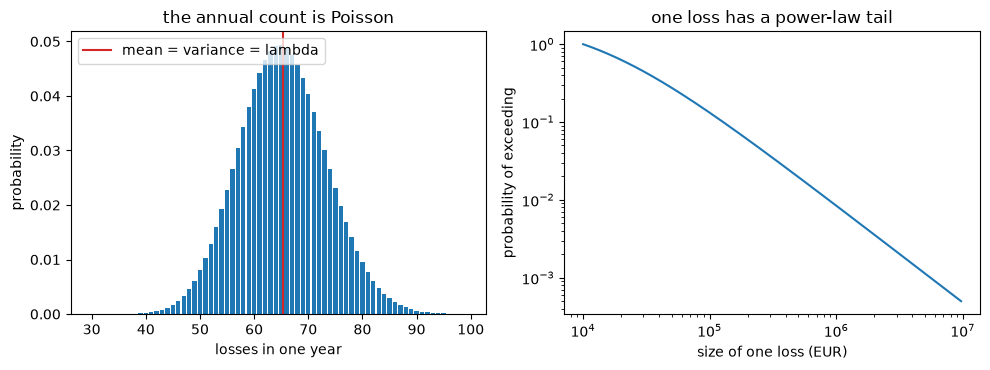

In [5]:
# Draw the Poisson count of a year and the survival of one loss, both from the engine
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.bar(k[30:100], pmf[30:100], color="tab:blue")
left.axvline(lam, color="tab:red", label="mean = variance = lambda")
left.set_xlabel("losses in one year")
left.set_ylabel("probability")
left.set_title("the annual count is Poisson")
left.legend(loc="upper left")
levels_grid = np.linspace(0.001, 0.9995, 400)
sizes_grid = distributions.severity_ppf("gpd", sev_params, levels_grid)
right.loglog(sizes_grid, 1 - levels_grid, color="tab:blue")
right.set_xlabel("size of one loss (EUR)")
right.set_ylabel("probability of exceeding")
right.set_title("one loss has a power-law tail")
fig.tight_layout()
plt.show()

The left panel is a bell around 65 losses: the count of a year is nearly the same every year, with P(N = 65) = 0.0494 at the peak and almost nothing below 45 or above 85. The right panel is the opposite: on logarithmic axes the survival of one loss is close to a straight line, the signature of a power law, so one loss in a thousand already costs EUR 5,559,249 and nothing in the data caps it. The count is tame and the size is wild, which is why the capital is decided by the severity. The panels do not show how the two combine over a year.

### Step 3: one year by hand

To see the compound sum at work, draw the count of a year, then that many sizes, then add them. The sizes are drawn by the inverse-cdf method: a uniform number in $(0, 1)$ goes through the engine's quantile function. The next cell does this for five years with a fixed seed and prints, for each year, how many losses there were, the largest, and the total. It is an illustration of the definition; the engine's own simulation in the next step is the method.

In [6]:
# Five years drawn by hand: a Poisson count, then that many sizes through the engine's quantile function
rng = np.random.default_rng(2026)
for year in range(1, 6):
    n_losses = int(rng.poisson(lam))
    sizes = distributions.severity_ppf("gpd", sev_params, rng.random(n_losses))
    print("year %d: N = %d | largest loss EUR %s | Z = EUR %s | largest share of Z %.2f" %
          (year, n_losses, format(sizes.max(), ",.0f"), format(sizes.sum(), ",.0f"), sizes.max() / sizes.sum()))

year 1: N = 57 | largest loss EUR 327,256 | Z = EUR 2,509,325 | largest share of Z 0.13
year 2: N = 73 | largest loss EUR 852,626 | Z = EUR 4,528,061 | largest share of Z 0.19
year 3: N = 58 | largest loss EUR 487,512 | Z = EUR 3,284,439 | largest share of Z 0.15
year 4: N = 69 | largest loss EUR 1,258,753 | Z = EUR 6,579,399 | largest share of Z 0.19
year 5: N = 57 | largest loss EUR 8,803,008 | Z = EUR 11,660,842 | largest share of Z 0.75


### Step 4: many years by the engine

`simulate_annual_losses` does exactly this for as many years as you ask, deterministically for a seed: the counts of all years come from one random stream and the sizes from a second one, and the result does not depend on how the work is chunked. The next cell simulates 100,000 years and compares the sample mean of $Z$ with its exact value $E[Z] = \lambda\, E[X]$ from `compound_poisson_moments`. The exact variance is infinite, so the sample mean converges slowly.

In [7]:
# Simulate 100,000 years and compare the sample mean with the exact mean of the compound sum
SEED = 17
sample = aggregate.simulate_annual_losses("poisson", (lam,), "gpd", sev_params, 100_000, SEED)
exact = aggregate.compound_poisson_moments(lam, "gpd", sev_params)
print("years simulated:", sample.n_years, "| seed:", sample.seed)
print("sample mean of Z (EUR):", format(sample.losses.mean(), ",.0f"))
print("exact mean of Z (EUR):", format(exact.mean, ",.0f"), "| exact variance:", exact.variance)
print("years with no loss:", int((sample.losses == 0).sum()), "| largest year EUR", format(sample.losses.max(), ",.0f"))

years simulated: 100000 | seed: 17
sample mean of Z (EUR): 6,180,404
exact mean of Z (EUR): 6,444,989 | exact variance: inf
years with no loss: 0 | largest year EUR 4,445,754,408


### Step 5: the 99.9% quantile and its error

The capital is the 99.9% quantile of $Z$: the loss exceeded in one year in a thousand. From $K$ simulated years, `mc_quantile` returns the order statistic of rank $\lceil K \alpha \rceil$ and a standard error from the binomial spread of the rank, with $s = \sqrt{K \alpha (1 - \alpha)}$ (Shevchenko, 2010: the error decays like $K^{-1/2}$). At $\alpha = 0.999$ only $K / 1000$ simulated years lie above the quantile, so the estimate rests on very few points. The next cell estimates the quantile with 10,000, 100,000 and 1,000,000 years.

In [8]:
# The Monte Carlo quantile and its standard error at three simulation sizes
rows = []
for n_years in (10_000, 100_000, 1_000_000):
    losses = aggregate.simulate_annual_losses("poisson", (lam,), "gpd", sev_params, n_years, SEED).losses
    q, se = aggregate.mc_quantile(losses, 0.999)
    rows.append((n_years, q, se))
    print("years %9d | years above the quantile %5d | q = EUR %s | standard error EUR %s (%.1f%%)" %
          (n_years, n_years // 1000, format(q, ",.0f"), format(se, ",.0f"), 100 * se / q))

years     10000 | years above the quantile    10 | q = EUR 142,539,576 | standard error EUR 63,069,007 (44.2%)
years    100000 | years above the quantile   100 | q = EUR 157,369,474 | standard error EUR 13,605,077 (8.6%)
years   1000000 | years above the quantile  1000 | q = EUR 163,999,415 | standard error EUR 4,936,818 (3.0%)


### Step 6: the true value

The case commits the true 99.9% quantile of this variant, computed once by the engine's Fourier method on a fine grid and checked by a Monte Carlo of 10,000,000 years (the next notebooks of this topic teach those methods). The next cell reads it, puts our three estimates beside it in units of their own standard error.

In [9]:
# Compare the three estimates with the committed true quantile
true_q = truth["annual_loss_quantile"]["value_eur"]
check = truth["annual_loss_quantile"]["mc_check"]
print(
    "true quantile (%s, grid step EUR %d): EUR %s" % (
        truth["annual_loss_quantile"]["method"], truth["annual_loss_quantile"]["grid_step_eur"],
        format(true_q, ",.0f")
    )
)
print(
    "committed Monte Carlo (%d years): EUR %s +/- %s" % (
        check["n_years"], format(check["value_eur"], ",.0f"), format(check["standard_error_eur"], ",.0f")
    )
)
for n_years, q, se in rows:
    print(
        "years %9d: ratio to the truth %.3f | distance in standard errors %+.2f" % (
            n_years, q / true_q, (q - true_q) / se
        )
    )

true quantile (fft, grid step EUR 1000): EUR 163,483,000
committed Monte Carlo (10000000 years): EUR 162,770,645 +/- 1,238,015
years     10000: ratio to the truth 0.872 | distance in standard errors -0.33
years    100000: ratio to the truth 0.963 | distance in standard errors -0.45
years   1000000: ratio to the truth 1.003 | distance in standard errors +0.10


The last cell draws the two lessons. On the left, the distribution of the simulated annual loss on a logarithmic axis: most years are small and a few are enormous, which is why the 99.9% quantile is far from the mean. On the right, the three Monte Carlo estimates with their standard errors against the true value: more years narrow the error band, slowly.

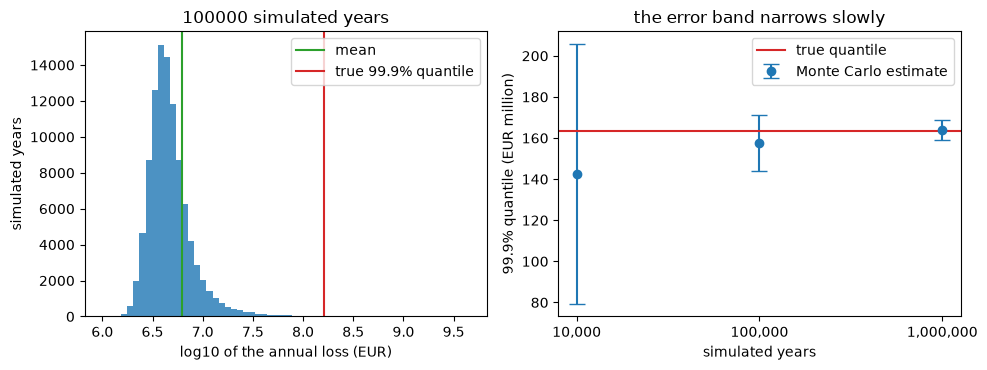

In [10]:
# Draw the distribution of the annual loss and the Monte Carlo estimates against the truth
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
log_losses = np.log10(sample.losses[sample.losses > 0])
left.hist(log_losses, bins=60, color="tab:blue", alpha=0.8)
left.axvline(np.log10(sample.losses.mean()), color="tab:green", label="mean")
left.axvline(np.log10(true_q), color="tab:red", label="true 99.9% quantile")
left.set_xlabel("log10 of the annual loss (EUR)")
left.set_ylabel("simulated years")
left.set_title("100000 simulated years")
left.legend()

sizes = [r[0] for r in rows]
right.errorbar(
    range(len(rows)), [r[1] / 1e6 for r in rows], yerr=[r[2] / 1e6 for r in rows], fmt="o", capsize=6,
    label="Monte Carlo estimate"
)
right.axhline(true_q / 1e6, color="tab:red", label="true quantile")
right.set_xticks(range(len(rows)))
right.set_xticklabels([format(n, ",") for n in sizes])
right.set_xlabel("simulated years")
right.set_ylabel("99.9% quantile (EUR million)")
right.set_title("the error band narrows slowly")
right.legend()
fig.tight_layout()
plt.show()

On the left, the histogram of 100,000 simulated years has a long right shoulder: most years cost a few million euro while a handful run past a hundred million, so the red line of the true quantile sits far to the right of the green mean. On the right, each estimate falls within one standard error of the truth and the bars shrink as years grow, but slowly, by about a factor of 13 for a hundredfold more years. The figure does not show that a different seed would move the 10,000-year estimate by tens of millions.

## Results

**Answer:** The synthetic bank suffers 65.2849 losses a year above EUR 10,000, and the true 99.9% quantile of its annual loss, the capital, is EUR 163,483,000. A Monte Carlo of 10,000 simulated years estimates EUR 142,539,576 with a standard error of 44.2%, 100,000 years give EUR 157,369,474 (8.6%) and 1,000,000 years give EUR 163,999,415 (3.0%): a capital within a few percent needs about a million simulated years.

- **Frequency and severity.** The bank suffers about 65.28 losses a year of EUR 10,000 or more. One loss has a median of EUR 26,438 and a 99.9% quantile of EUR 5.56 million; its mean is finite (EUR 98,721) and its second moment is infinite, because the tail index 0.8 times 2 is above 1.
- **The compound sum.** Five years drawn by hand give totals from EUR 2.5 million to EUR 11.7 million, and in year 5 a single loss makes 75% of the total. Over 100,000 simulated years the sample mean is EUR 6.18 million against the exact EUR 6.44 million, 4% below it, and the largest simulated year is EUR 4.4 billion, about 690 times the mean. With an infinite variance the mean itself is slow to settle.
- **The quantile.** The 99.9% estimates are EUR 142.5 million, 157.4 million and 164.0 million with 10,000, 100,000 and 1,000,000 years, with standard errors of 44%, 8.6% and 3.0% of the estimate. The committed true quantile is EUR 163.48 million, and the committed Monte Carlo of 10,000,000 years gives EUR 162.77 million with a standard error of EUR 1.24 million. Each of our estimates lies within one standard error of the truth. A hundred times more years cut the error by a factor of about 13, not 100: the error decays like the square root of the number of years.

What this notebook does not show: how the engine computes the exact distribution instead of simulating it (notebook 03), what changes when the bank records only the losses above a threshold (notebook 02), and the closed-form approximation of the quantile (notebook 04).

## Summary

- The annual operational loss is a compound sum: a Poisson number of losses, each with a generalised Pareto size, added up.
- With a tail index near 1 a few losses carry most of a bad year, the variance can be infinite, and even the mean converges slowly.
- The capital is a 99.9% quantile of the annual loss; a Monte Carlo estimate rests on only one year in a thousand of the simulation and its standard error falls like the square root of the number of years.
- The case commits the true quantile because the generator is known, so every capital estimate of the next notebooks can be judged against it.

**What to try next.** Change `SEED` and watch the estimate with 10,000 years move by tens of millions of euro while the one with 1,000,000 years barely moves. Then load `xi-1-1.json`, whose tail index is 1.1, and ask the engine for `compound_poisson_moments`: the mean is infinite. Continue with notebook 02.

## References

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk, Basel Committee on Banking Supervision. https://www.bis.org/publ/bcbs160.htm
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40. https://arxiv.org/abs/1008.1108 and https://doi.org/10.21314/JOP.2010.077